# 06. Augmentacja

**Krok procesu:** 5. Augmentacja, potem bramka 6.

Augmentacja dokłada do zbioru treningowego losowo zmienione kopie dłoni. Działa tylko w treningu.
Walidacja, test i telefon dostają dane bez zmian (poza preprocessingiem wybranym w `05_preprocessing.ipynb`).

Przekształcenia robimy na surowych punktach, przed preprocessingiem, tak jak zmieniałby je prawdziwy kadr:
- obrót dłoni o kąt z zakresu od -30 do 30 stopni,
- zmiana proporcji osi x do y od 0.8 do 1.25 (inny kształt kadru),
- odbicie lustrzane z prawdopodobieństwem 0.5 (lewa i prawa dłoń, kamera przednia),
- szum o odchyleniu 1% wielkości dłoni (drgania detektora).

Zakresy są celowo węższe niż w teście obciążeniowym (45 stopni, proporcje 0.75 do 1.33). Losowania są niezależne.
Gdyby augmentacja była identyczna z testem, wynik testu obciążeniowego byłby zawyżony.

| Wariant | Co robi |
|---|---|
| A1 | 1 losowa kopia na każdą dłoń (2x więcej danych) |
| A2 | 2 losowe kopie (3x więcej danych). Sprawdza, czy więcej augmentacji opłaca się przy kosztach energii |

In [1]:
import sys
sys.path.insert(0, "../src")

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from features import normalise
from labels import FINGER_JOINTS, HAND_EDGES
from pipeline import PREPROCESS, augment, gate, load_split, run_experiment, stress_set

FIG = Path("../reports/figures")
GATES = Path("../experiments/gates.json")
LOG = Path("../experiments/log.csv")
sns.set_theme(style="whitegrid")

gates = json.loads(GATES.read_text())
prev_id, prep_name = gates["preprocessing"]["experiment_id"], gates["preprocessing"]["preprocess"]
prep = PREPROCESS[prep_name]
print("Start od:", prev_id, prep_name)

lm_tr, y_tr, d_tr = load_split("train")
lm_va, y_va, _ = load_split("val")
lm_st = stress_set(lm_va)
X_va, X_st = prep(lm_va), prep(lm_st)

def mlp_default(seed):
    return make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(128, 64), early_stopping=True,
                                                         max_iter=50, random_state=seed))

current = pd.read_csv(LOG).set_index("experiment_id").loc[prev_id].to_dict()
current_id = prev_id

Start od: P1 wrist_scale


## Jak wyglądają augmentowane dłonie

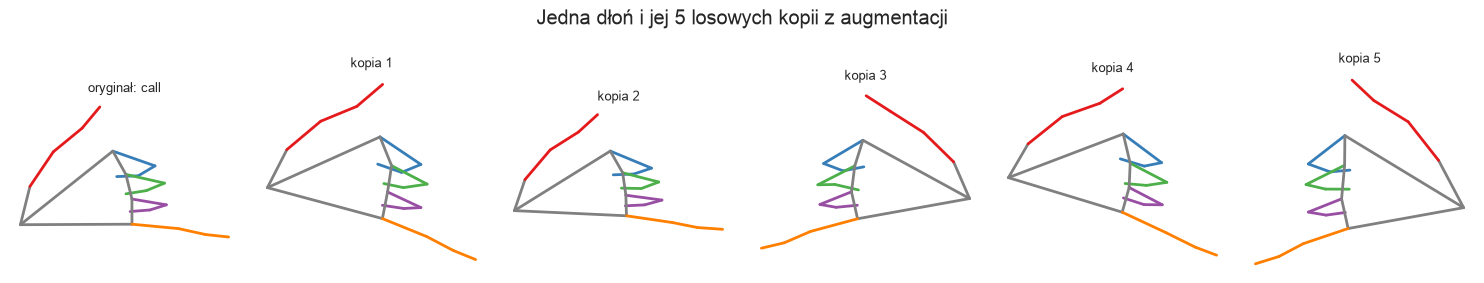

In [2]:
FINGER_COLOR = dict(zip(FINGER_JOINTS, sns.color_palette("Set1", 5)))
EDGE_FINGER = {e: next((f for f, j in FINGER_JOINTS.items() if set(e) <= set(j)), None) for e in HAND_EDGES}

def draw(ax, lm, title):
    lm = normalise(lm[None])[0]
    for e in HAND_EDGES:
        f = EDGE_FINGER[e]
        ax.plot(lm[list(e), 0], -lm[list(e), 1], lw=2, color=FINGER_COLOR[f] if f else "grey")
    ax.set_title(title, fontsize=9); ax.set_aspect("equal"); ax.axis("off")

i = 7
one = np.repeat(lm_tr[i:i + 1], 5, axis=0)
aug, _ = augment(one, np.zeros(5), np.random.default_rng(1))
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
draw(axes[0], lm_tr[i], f"oryginał: {d_tr.label[i]}")
for k in range(5):
    draw(axes[k + 1], aug[5 + k], f"kopia {k + 1}")
plt.suptitle("Jedna dłoń i jej 5 losowych kopii z augmentacji")
plt.tight_layout(); plt.savefig(FIG / "augmentation_examples.png", dpi=130); plt.show()

## Eksperymenty

In [3]:
results, decisions = {prev_id: current}, []
for exp_id, copies in [("A1", 1), ("A2", 2)]:
    lm_aug, y_aug = augment(lm_tr, y_tr, np.random.default_rng(0), copies=copies)
    res, _ = run_experiment(exp_id, "augmentation", mlp_default, prep(lm_aug), y_aug, X_va, y_va, X_st,
                            notes={"model": "MLP 128-64, domyślne parametry",
                                   "notes": f"{prep_name} + augmentacja, {copies} kopia/kopie (obrót 30, proporcje 0.8-1.25, odbicie 0.5, szum 1%)"})
    passed, reasons = gate(current, res)
    decisions.append({"eksperyment": exp_id, "porównanie z": current_id, "bramka": "przechodzi" if passed else "odrzucony",
                      "powody": "; ".join(reasons)})
    results[exp_id] = res
    if passed:
        current, current_id = res, exp_id
    del lm_aug, y_aug

pd.DataFrame(decisions)

[codecarbon INFO @ 17:15:08] offline tracker init


[codecarbon WARNING @ 17:15:08] Multiple instances of codecarbon are allowed to run at the same time.


,eksperyment,porównanie z,bramka,powody
0,A1,P1,przechodzi,"stress F1 +0.0429 (próg szumu 0.0260), val F1 ..."
1,A2,A1,odrzucony,"stress F1 +0.0004 (próg szumu 0.0010), val F1 ..."


In [4]:
table = pd.DataFrame(results).T[["train_samples", "val_macro_f1", "val_macro_f1_std", "val_stress_macro_f1",
                                 "val_stress_macro_f1_std", "train_time_s", "energy_kwh", "co2_g", "model_size_kb",
                                 "latency_ms"]].astype(float)
table.style.format({"train_samples": "{:,.0f}", "val_macro_f1": "{:.4f}", "val_macro_f1_std": "{:.4f}",
                    "val_stress_macro_f1": "{:.4f}", "val_stress_macro_f1_std": "{:.4f}", "train_time_s": "{:.1f}",
                    "energy_kwh": "{:.6f}", "co2_g": "{:.3f}", "model_size_kb": "{:.0f}", "latency_ms": "{:.3f}"})

,train_samples,val_macro_f1,val_macro_f1_std,val_stress_macro_f1,val_stress_macro_f1_std,train_time_s,energy_kwh,co2_g,model_size_kb,latency_ms
P1,"612,590",0.9931,0.0002,0.9469,0.0130,37.6,0.000154,0.102,175,0.137
A1,"1,225,180",0.9934,0.0003,0.9898,0.0003,96.8,0.000394,0.261,175,0.136
A2,"1,837,770",0.9933,0.0004,0.9902,0.0005,123.7,0.000503,0.333,175,0.135


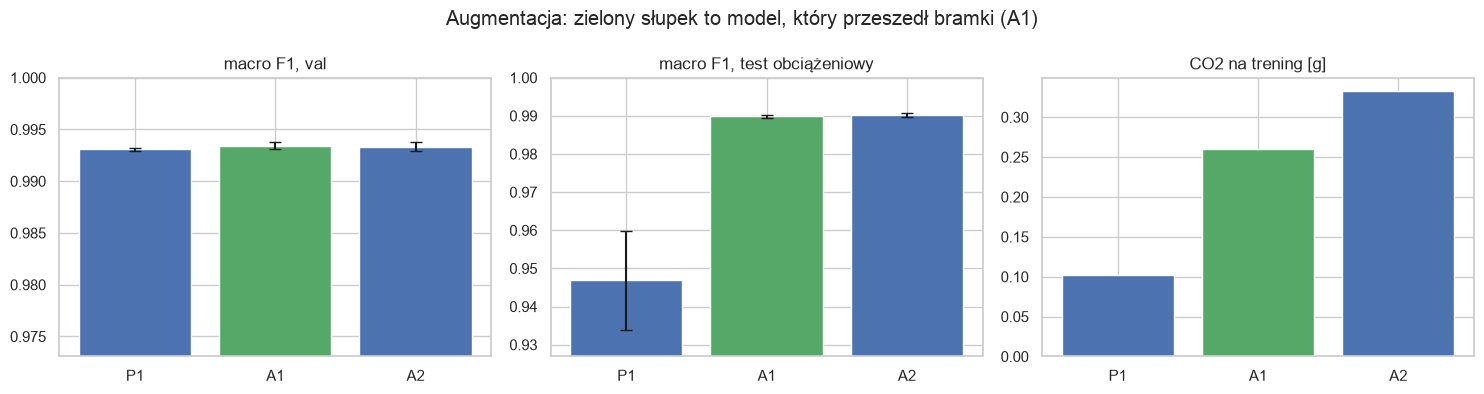

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
order = list(results)
for ax, col, title in zip(axes, ["val_macro_f1", "val_stress_macro_f1", "co2_g"],
                          ["macro F1, val", "macro F1, test obciążeniowy", "CO2 na trening [g]"]):
    has_std = f"{col}_std" in table
    ax.bar(order, table.loc[order, col], yerr=table.loc[order, f"{col}_std"] if has_std else None, capsize=4,
           color=[sns.color_palette()[2] if i == current_id else sns.color_palette()[0] for i in order])
    ax.set_title(title)
    if has_std:
        ax.set_ylim(max(0, table.loc[order, col].min() - 0.02), 1.0)
plt.suptitle(f"Augmentacja: zielony słupek to model, który przeszedł bramki ({current_id})")
plt.tight_layout(); plt.savefig(FIG / "augmentation_comparison.png", dpi=150); plt.show()

In [6]:
gates["augmentation"] = {"experiment_id": current_id, "preprocess": prep_name,
                         "augment_copies": {"A1": 1, "A2": 2}.get(current_id, 0)}
GATES.write_text(json.dumps(gates, indent=2, ensure_ascii=False))
print("Do kolejnego kroku idzie:", current_id)

Do kolejnego kroku idzie: A1


## Wnioski

- **A1 przechodzi bramkę.** Jedna losowa kopia każdej dłoni podnosi test obciążeniowy z 0.947 do 0.990 (+0.043
  przy progu szumu 0.026). Val się nie pogarsza (0.9931 -> 0.9934). Rozmiar modelu i czas predykcji bez zmian,
  więc telefon nie płaci nic więcej.
- **Koszt jest w treningu.** Dwa razy więcej danych to trening 97 s zamiast 38 s i 0.26 g zamiast 0.10 g CO2
  (około 2 m jazdy samochodem). Zgodnie z regułą bramki akceptujemy to, bo zysk jakości jest realny.
- **A2 odrzucony.** Druga kopia daje +0.0004 na teście obciążeniowym, czyli mniej niż szum (0.0010), a trening
  kosztuje kolejne 0.07 g CO2. Więcej augmentacji przestało się opłacać już po pierwszej kopii.
- **Odpowiedź na pytanie z kroku 05.** Augmentacja daje tę samą odporność co obrót do pionu (0.990 w obu
  przypadkach), ale bez spadku na val (0.9934 zamiast 0.9913). Model uczy się przechylonych dłoni z danych, zamiast
  tracić informację przez sztywny obrót. Odrzucenie P2 przez bramkę okazało się dobrą decyzją.

**Do strojenia idzie A1** (preprocessing `wrist_scale` + 1 kopia augmentacji).